本 notebook 是 [M02.2 微积分与矩阵微积分](../notes/02-matrix-calculus.qmd) 的实例讲解。

1. 1. 梯度与 Jacobian 的形状
2. 2. 两层映射的手工反传
3. 3. Taylor 与差分步长
4. 4. Hessian 与约束驻点

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats

from semiai.plotting import BLUE, GRAY, ORANGE, use_style
from semiai.testing import numerical_gradient

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 梯度与 Jacobian 的形状

把向量链式法则写成矩阵乘法，并与逐分量差分比较。这里使用分子布局：输出分量对应行。

In [2]:
A = rng.normal(size=(4, 3))
x = rng.normal(size=3)
z = A @ x
J = np.diag(np.cos(z)) @ A
g = J.T @ np.ones(4)
g_fd = numerical_gradient(lambda q: np.sin(A @ q).sum(), x)
print("Jacobian shape:", J.shape, "gradient shape:", g.shape)
print("链式法则梯度误差:", np.max(np.abs(g - g_fd)))
assert np.allclose(g, g_fd, atol=1e-8)

Jacobian shape: (4, 3) gradient shape: (3,)
链式法则梯度误差: 1.9494850178602974e-10


读法：Jacobian 为 4×3，标量目标的梯度为长度 3 的列向量；反传使用转置 Jacobian 把输出权重传回输入。

## 2. 两层映射的手工反传

用 tanh 隐层和线性输出构造最小两层模型。只比较数学梯度与中心差分，不依赖自动微分框架。

In [3]:
X = rng.normal(size=(9, 3))
y = rng.normal(size=9)
W = rng.normal(scale=0.2, size=(3, 4))
v = rng.normal(scale=0.2, size=4)


def loss(flat):
    w = flat[:12].reshape(3, 4)
    vv = flat[12:]
    return np.mean((np.tanh(X @ w) @ vv - y) ** 2) / 2


H = np.tanh(X @ W)
r = H @ v - y
gv = H.T @ r / len(X)
gW = X.T @ ((r[:, None] * v[None, :]) * (1 - H**2)) / len(X)
params = np.r_[W.ravel(), v]
analytic = np.r_[gW.ravel(), gv]
fd = numerical_gradient(loss, params)
print("参数个数:", len(params), "最大梯度误差:", np.max(np.abs(analytic - fd)))
assert np.allclose(analytic, fd, atol=1e-8)

参数个数: 16 最大梯度误差: 1.931892146256331e-11


读法：广播实现了外积，样本平均因子只出现一次。若漏掉 tanh 的导数或把样本轴求和写错，有限差分比较会直接失败。

## 3. Taylor 与差分步长

观察截断误差和舍入误差的竞争。中间区间误差随步长平方下降，步长太小后误差反而上升。

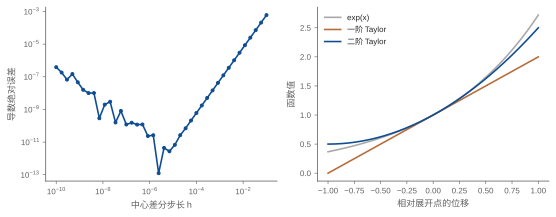

              h  absolute derivative error
0  1.000000e-01               6.036277e-04
1  1.425103e-03               1.226531e-07
2  2.030918e-05               2.642830e-11
3  2.894266e-07               1.176161e-10
4  4.124626e-09               1.011637e-08


该组步长中的最小误差: 1.2428946760678627e-13


In [4]:
x0 = 1.2
hs = np.logspace(-1, -10, 40)
errors = np.abs((np.sin(x0 + hs) - np.sin(x0 - hs)) / (2 * hs) - np.cos(x0))
delta = np.linspace(-1, 1, 150)
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.1))
axes[0].loglog(hs, errors, "o-", ms=3, color=BLUE)
axes[0].set(xlabel="中心差分步长 h", ylabel="导数绝对误差")
axes[1].plot(delta, np.exp(delta), color=GRAY, label="exp(x)")
axes[1].plot(delta, 1 + delta, color=ORANGE, label="一阶 Taylor")
axes[1].plot(delta, 1 + delta + delta**2 / 2, color=BLUE, label="二阶 Taylor")
axes[1].set(xlabel="相对展开点的位移", ylabel="函数值")
axes[1].legend()
fig.tight_layout()
plt.show()

print(pd.DataFrame({"h": hs[::8], "absolute derivative error": errors[::8]}))
print("该组步长中的最小误差:", errors.min())

读法：误差谷底与函数尺度、精度和差分格式有关；不能把最小的 h 直接当作最准确的梯度。

## 4. Hessian 与约束驻点

二次型的 Hessian 是常矩阵。单位球约束下的最小 Rayleigh 商是最小特征值，并满足 Lagrange 驻点方程。

In [5]:
B = np.array([[3.0, 0.6], [0.6, 1.0]])
evals, evecs = np.linalg.eigh(B)
u = evecs[:, 0]
print("最小 Rayleigh 商:", u @ B @ u, "最小特征值:", evals[0])
print("约束驻点残差:", np.linalg.norm(B @ u - evals[0] * u))
print("二次目标 Hessian 特征值:", np.linalg.eigvalsh(B))
assert np.allclose(B @ u, evals[0] * u)

最小 Rayleigh 商: 0.8338096210309398 最小特征值: 0.8338096210309399
约束驻点残差: 2.7755575615628914e-17
二次目标 Hessian 特征值: [0.83380962 3.16619038]


读法：驻点条件只给出候选点；此例还利用特征值排序确认了全局最小值。一般非凸约束问题不能只解驻点方程就宣布完成最优化。

## 小结

梯度、Jacobian 和 Hessian 是不同形状的局部线性或二次信息。微分表达式帮助识别正确的转置，链式法则负责组合，有限差分负责独立核对。约束优化增加了可行方向的限制，驻点方程仍需配合适用条件解释。